# WBC Classification Pipeline
Clovers Aderomi Akitoye | Artificial Intelligence as a Medical Device | University of Hull

Binary classification of breast tumours as malignant or benign using the Wisconsin Breast Cancer dataset. The dataset contains 569 patient samples with 30 features derived from fine needle aspiration (FNA) of breast masses, describing the geometric and morphological properties of cell nuclei.

## Imports

Every library the notebook uses is declared here in one block. External packages (imbalanced-learn, torch, spacy, biopython) were installed separately via pip before running.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import joblib
from collections import Counter
from datetime import datetime, timedelta

# sklearn: preprocessing
from sklearn.preprocessing import MinMaxScaler, StandardScaler, MaxAbsScaler
from sklearn.impute import SimpleImputer

# sklearn: feature selection
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, RFE

# sklearn: model selection and validation
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

# sklearn: models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA

# sklearn: metrics
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             recall_score, precision_score, adjusted_rand_score)

# sklearn: feature importance
from sklearn.inspection import permutation_importance

# sklearn: clustering
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.cluster import DBSCAN

# sklearn: pipeline
from sklearn.pipeline import Pipeline as SkPipeline

# imbalanced-learn
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.pipeline import Pipeline

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

# NLP / systematic review
import spacy
from Bio import Entrez

In [2]:
# checking working directory so the csv file can be found
cwd = os.getcwd()
cwd

'~/Library/CloudStorage/OneDrive-hull.ac.uk'

In [3]:
# load the dataset
filename = 'mod_wbc_data.csv'
wbc_df = pd.read_csv(filename)
wbc_df.head(), wbc_df.shape

(   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
 0        17.99         10.38          122.80     1001.0              NaN   
 1        20.57         17.77          132.90     1326.0              NaN   
 2        19.69         21.25          130.00     1203.0              NaN   
 3        11.42         20.38           77.58      386.1           0.1425   
 4        20.29         14.34          135.10     1297.0              NaN   
 
    mean compactness  mean concavity  mean concave points  mean symmetry  \
 0           0.27760          0.3001              0.14710         0.2419   
 1           0.07864          0.0869              0.07017         0.1812   
 2           0.15990          0.1974              0.12790         0.2069   
 3           0.28390          0.2414              0.10520         0.2597   
 4           0.13280          0.1980              0.10430         0.1809   
 
    mean fractal dimension  ...  worst texture  worst perimeter  worst area  \

In [4]:
print('The shape of the dataset is:', wbc_df.shape)

The shape of the dataset is: (569, 31)


In [5]:
# checking data types. all features should be numeric
wbc_df.dtypes

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

In [6]:
# summary statistics to check ranges, means, and spot anything unusual
wbc_df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
count,569.000000,569.000000,569.000000,569.000000,285.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.095784,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014299,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.085230,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.094950,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.104200,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


### Class Balance

Checking how many benign vs malignant samples are in the dataset. If one class heavily outweighs the other, the model could just predict the majority class and still look accurate. This matters because in healthcare, missing a malignant case is far worse than a false alarm.

In [7]:
# Check for missing values
miss_vals = wbc_df.isnull().sum()
print("Missing values per column:")
print(miss_vals)

# Or see total missing values
total_missing = miss_vals.sum()
print(f"Total missing values: {total_missing}")

Missing values per column:
mean radius                  0
mean texture                 0
mean perimeter               0
mean area                    0
mean smoothness            284
mean compactness             0
mean concavity               0
mean concave points          0
mean symmetry                0
mean fractal dimension       0
radius error                 0
texture error                0
perimeter error              0
area error                   0
smoothness error             0
compactness error            0
concavity error              0
concave points error         0
symmetry error              28
fractal dimension error      0
worst radius                 0
worst texture                0
worst perimeter              0
worst area                   0
worst smoothness             0
worst compactness            0
worst concavity              0
worst concave points         0
worst symmetry               0
worst fractal dimension      0
diagnosis                    0
dtype: int64

In [8]:
# 0 = malignant, 1 = benign
wbc_df['diagnosis'].value_counts()

diagnosis
1    357
0    212
Name: count, dtype: int64

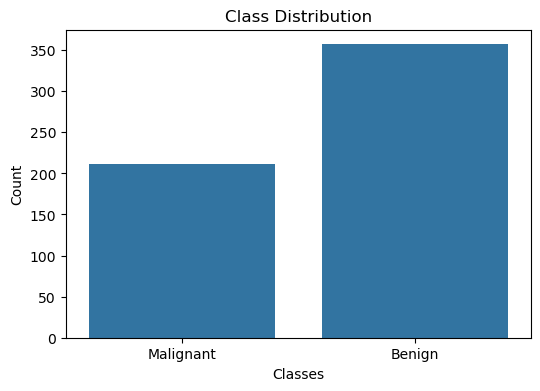

In [9]:
plt.figure(figsize=(6,4))
sns.countplot(x = wbc_df['diagnosis'])
plt.xticks(ticks=[0,1], labels=["Malignant", "Benign"])
plt.title('Class Distribution')
plt.xlabel('Classes')
plt.ylabel('Count')
plt.show()

### Feature and Target Split

Separating the data into features (X) and target (y) so the model only sees the input measurements, not the diagnosis label, during training. Then plotting histograms for every feature split by class to see which ones visually separate malignant from benign.

In [10]:
# X = features (all columns except diagnosis)
X = wbc_df.drop(columns=['diagnosis'])

# y = target (just the diagnosis column)
y = wbc_df['diagnosis']

# Check the shapes
print('Shape of X (features):', X.shape)
print('Shape of y (target):', y.shape)

Shape of X (features): (569, 30)
Shape of y (target): (569,)


## Session 02

Before training any models, the features need cleaning. Highly correlated features are redundant because they carry the same information twice, which can hurt model performance and make interpretation harder. Missing values need handling. And class imbalance needs addressing so the model does not just learn to predict the majority class.

### Correlation Analysis

If two features are very highly correlated (above 0.9), one of them is essentially a copy of the other. Keeping both adds noise without adding information. The heatmap below shows all pairwise correlations so I can identify which features to drop.

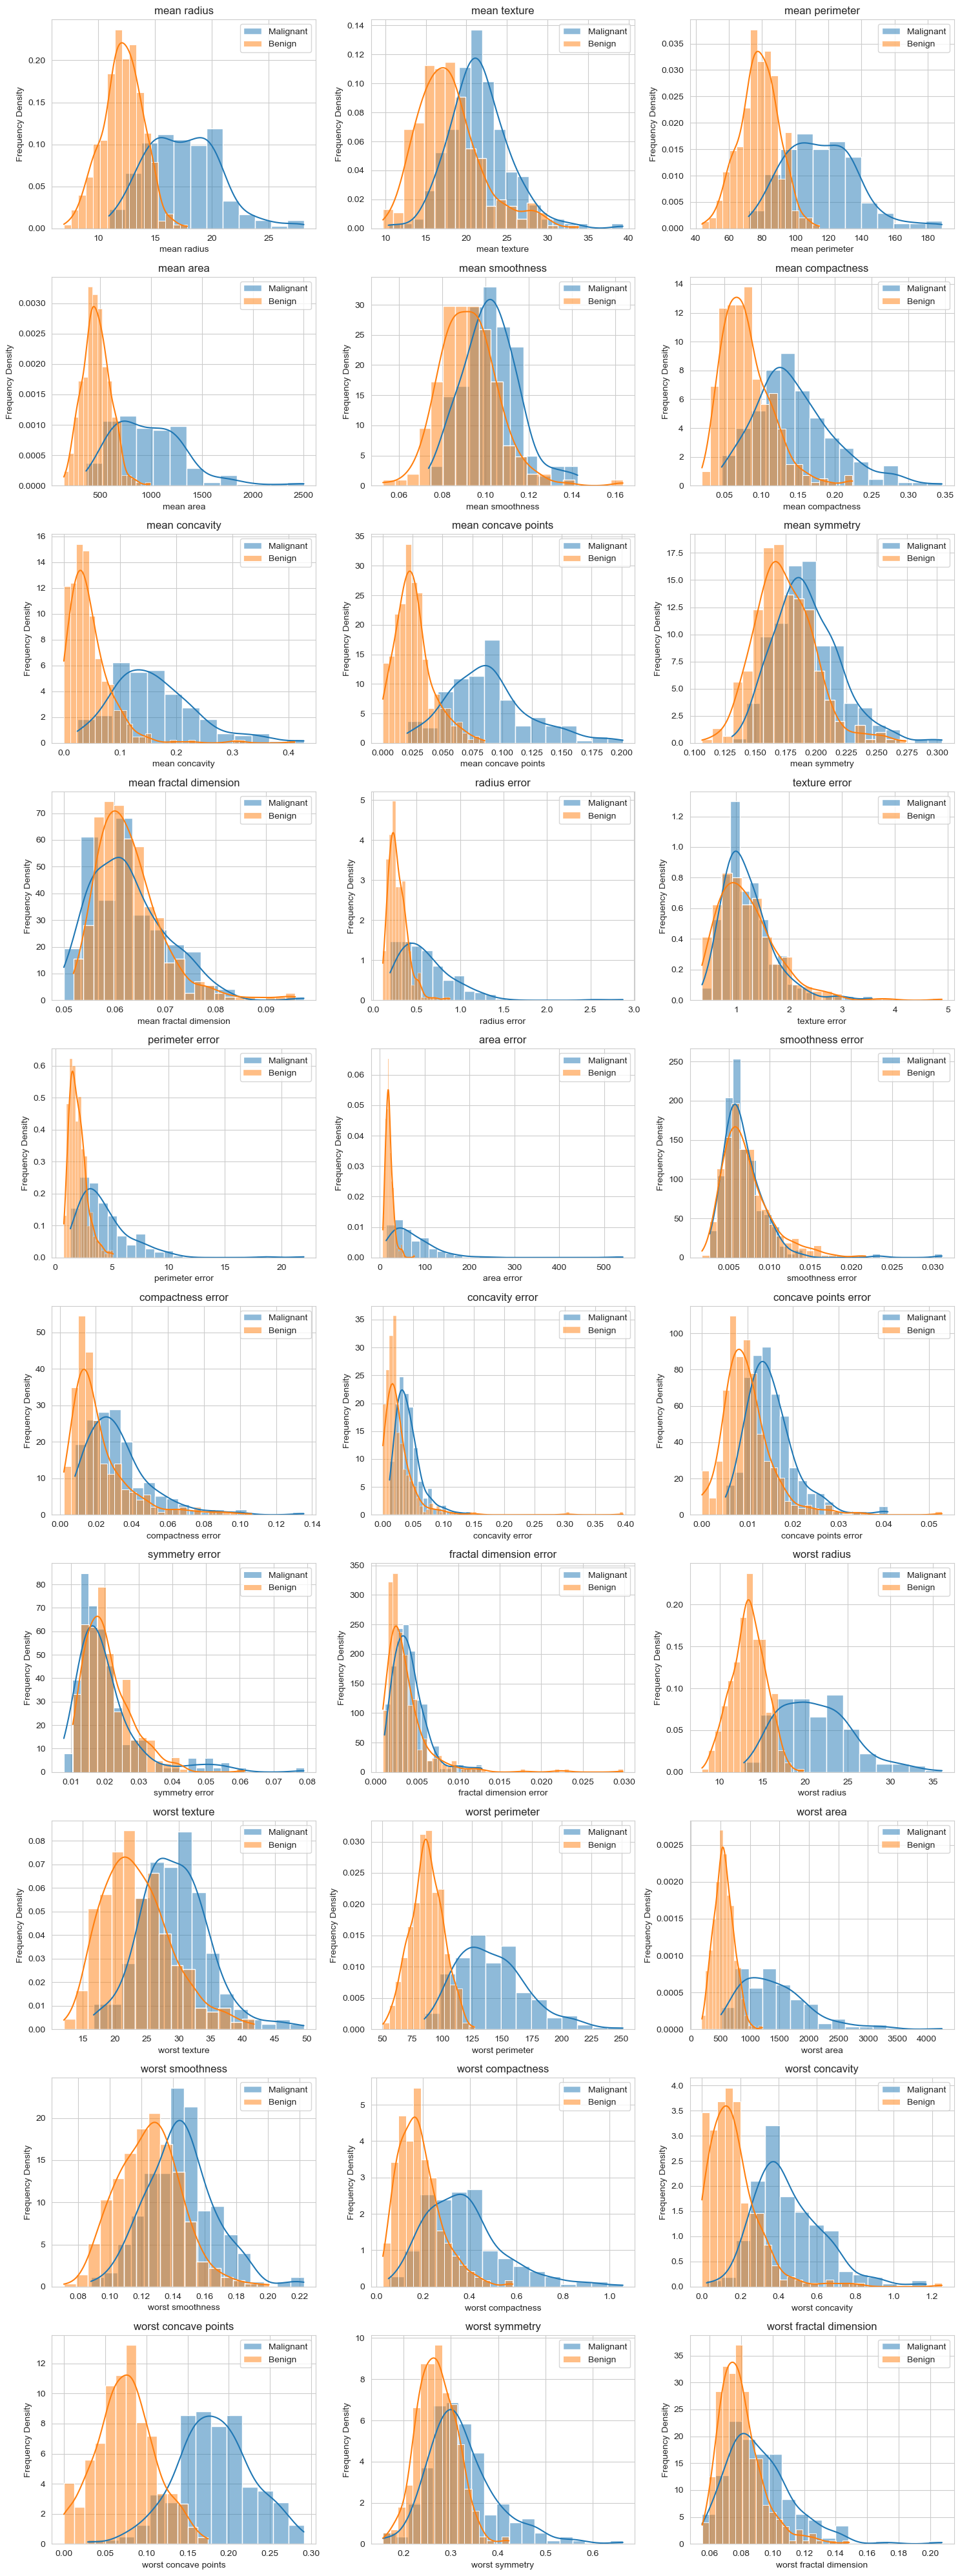

In [11]:
# Set up
features = X.columns  # Get list of all feature names
classes = y.unique()  # Get unique class labels (0 and 1)
sns.set_style('whitegrid')  # Make plots prettier

# Create grid of subplots
num_features = len(features)
num_cols = 3  # 3 plots per row
num_rows = -(-num_features // num_cols)  # Ceiling division

fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, num_rows * 4))
axes = axes.flatten()  # Makes it easier to loop through

# Define readable labels
class_names = {0: "Malignant", 1: "Benign"}

# Create histograms for each feature
for i, feature in enumerate(features):
    for cls in classes:
        sns.histplot(
            X[y == cls][feature],  # Filter by class
            label=class_names[cls],  # Label for legend
            kde=True,  # Add smooth curve
            stat="density",  # Normalize y-axis
            common_norm=False,  # Prevents class imbalance skewing
            ax=axes[i],  # Which subplot to draw on
            alpha=0.5  # Transparency
        )
    axes[i].set_title(feature)
    axes[i].set_ylabel('Frequency Density')
    axes[i].legend()

# Remove empty subplots if any
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

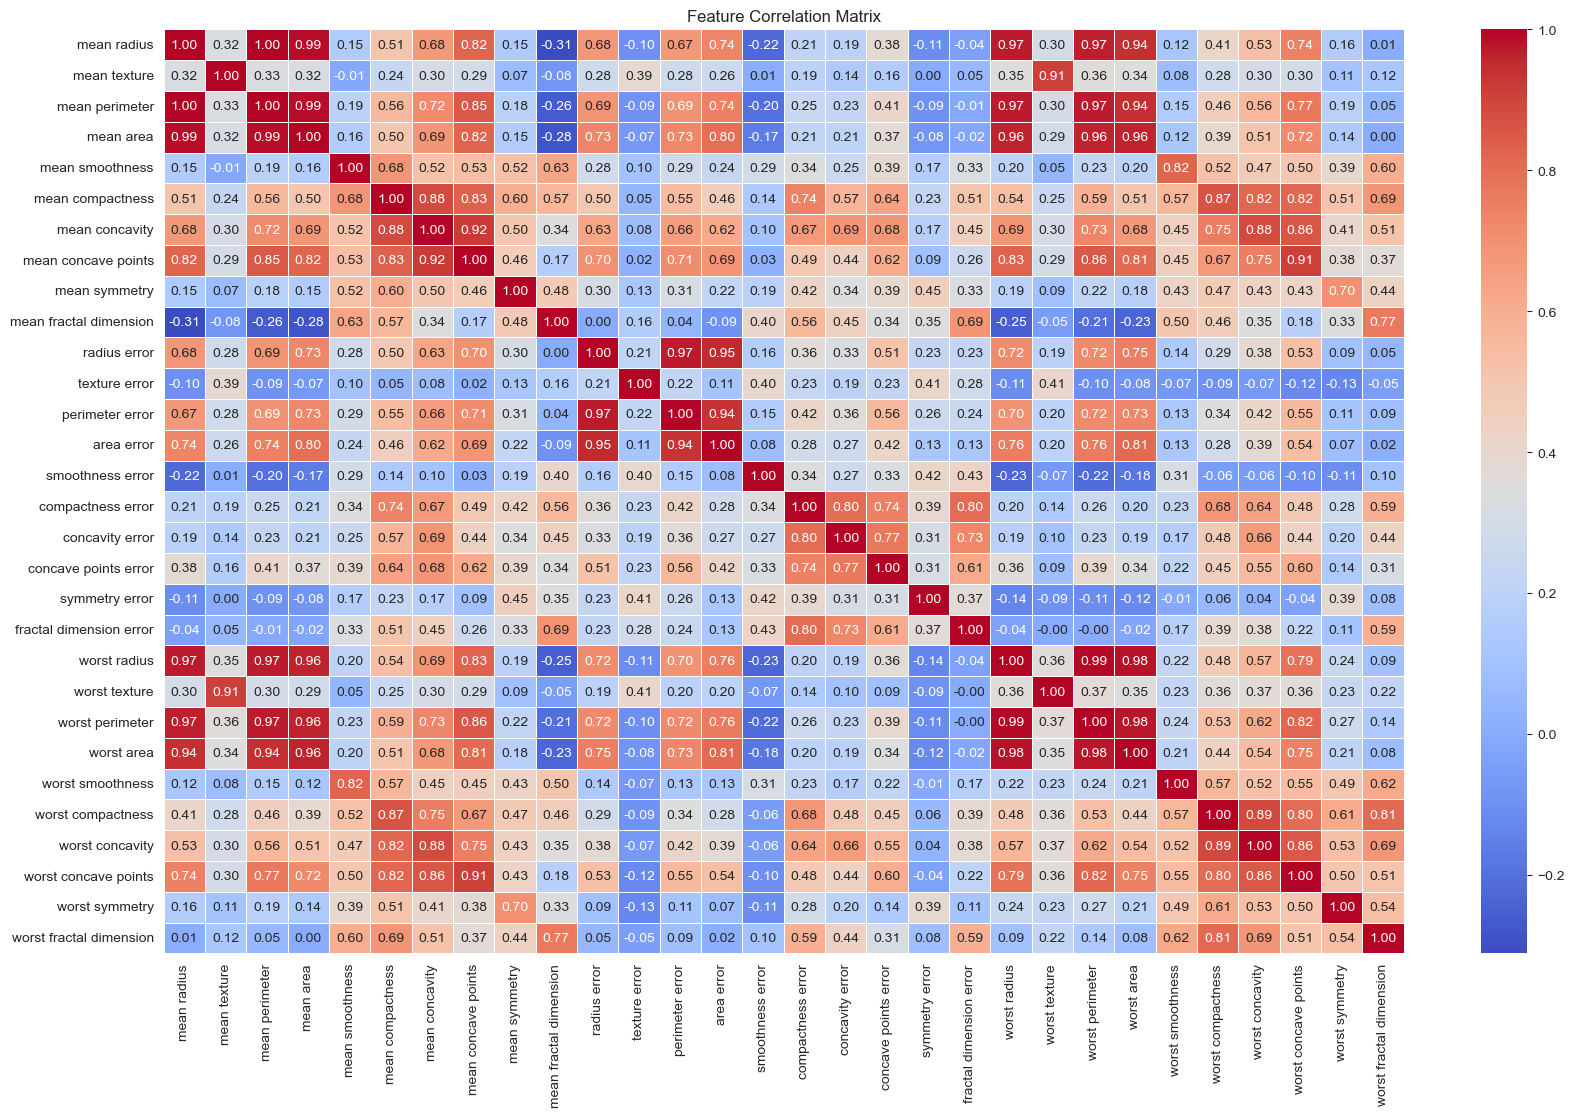

In [12]:
cor_mat = X.corr()

plt.figure(figsize=(20, 12))
sns.heatmap(cor_mat, annot=True, fmt=".2f", cmap="coolwarm", linewidth=0.5)
plt.title("Feature Correlation Matrix")
plt.show()

### Removing Highly Correlated Features

Dropping one feature from each highly correlated pair. The choice of which to remove is somewhat arbitrary when both carry the same signal, but keeping the simpler or more interpretable one where possible. After removal, the correlation matrix is replotted to confirm no high correlations remain.

In [13]:
# Get absolute correlation values
cor_mat_abs = X.corr().abs()

# Keep only upper triangle
upper_tri = cor_mat_abs.where(np.triu(np.ones(cor_mat_abs.shape), k=1).astype(bool))

# Set threshold
threshold = 0.9

# Extract highly correlated pairs
high_cor_pairs = [
    (col, row)
    for col in upper_tri.columns
    for row in upper_tri.index
    if upper_tri.loc[row, col] > threshold
]

# Get unique features involved
unique_high_cor_feat = list(set([feature for pair in high_cor_pairs for feature in pair]))

# Print results
print(f"Highly correlated feature pairs (>|{threshold}|):")
for pair in high_cor_pairs:
    print(pair)

print("Unique features involved in high correlation:")
print(unique_high_cor_feat)

Highly correlated feature pairs (>|0.9|):
('mean perimeter', 'mean radius')
('mean area', 'mean radius')
('mean area', 'mean perimeter')
('mean concave points', 'mean concavity')
('perimeter error', 'radius error')
('area error', 'radius error')
('area error', 'perimeter error')
('worst radius', 'mean radius')
('worst radius', 'mean perimeter')
('worst radius', 'mean area')
('worst texture', 'mean texture')
('worst perimeter', 'mean radius')
('worst perimeter', 'mean perimeter')
('worst perimeter', 'mean area')
('worst perimeter', 'worst radius')
('worst area', 'mean radius')
('worst area', 'mean perimeter')
('worst area', 'mean area')
('worst area', 'worst radius')
('worst area', 'worst perimeter')
('worst concave points', 'mean concave points')
Unique features involved in high correlation:
['radius error', 'mean texture', 'mean area', 'worst concave points', 'perimeter error', 'worst texture', 'worst area', 'area error', 'mean radius', 'mean concave points', 'worst radius', 'mean per

In [14]:
feats_to_remove = ['mean perimeter', 'mean area', 'worst radius', 'worst perimeter', 'worst area', 'perimeter error', 'area error', 'worst texture', 'mean concavity', 'worst concave points']
X_rem = X.drop(columns = feats_to_remove)
print(X.shape)
X_rem.shape

(569, 30)


(569, 20)

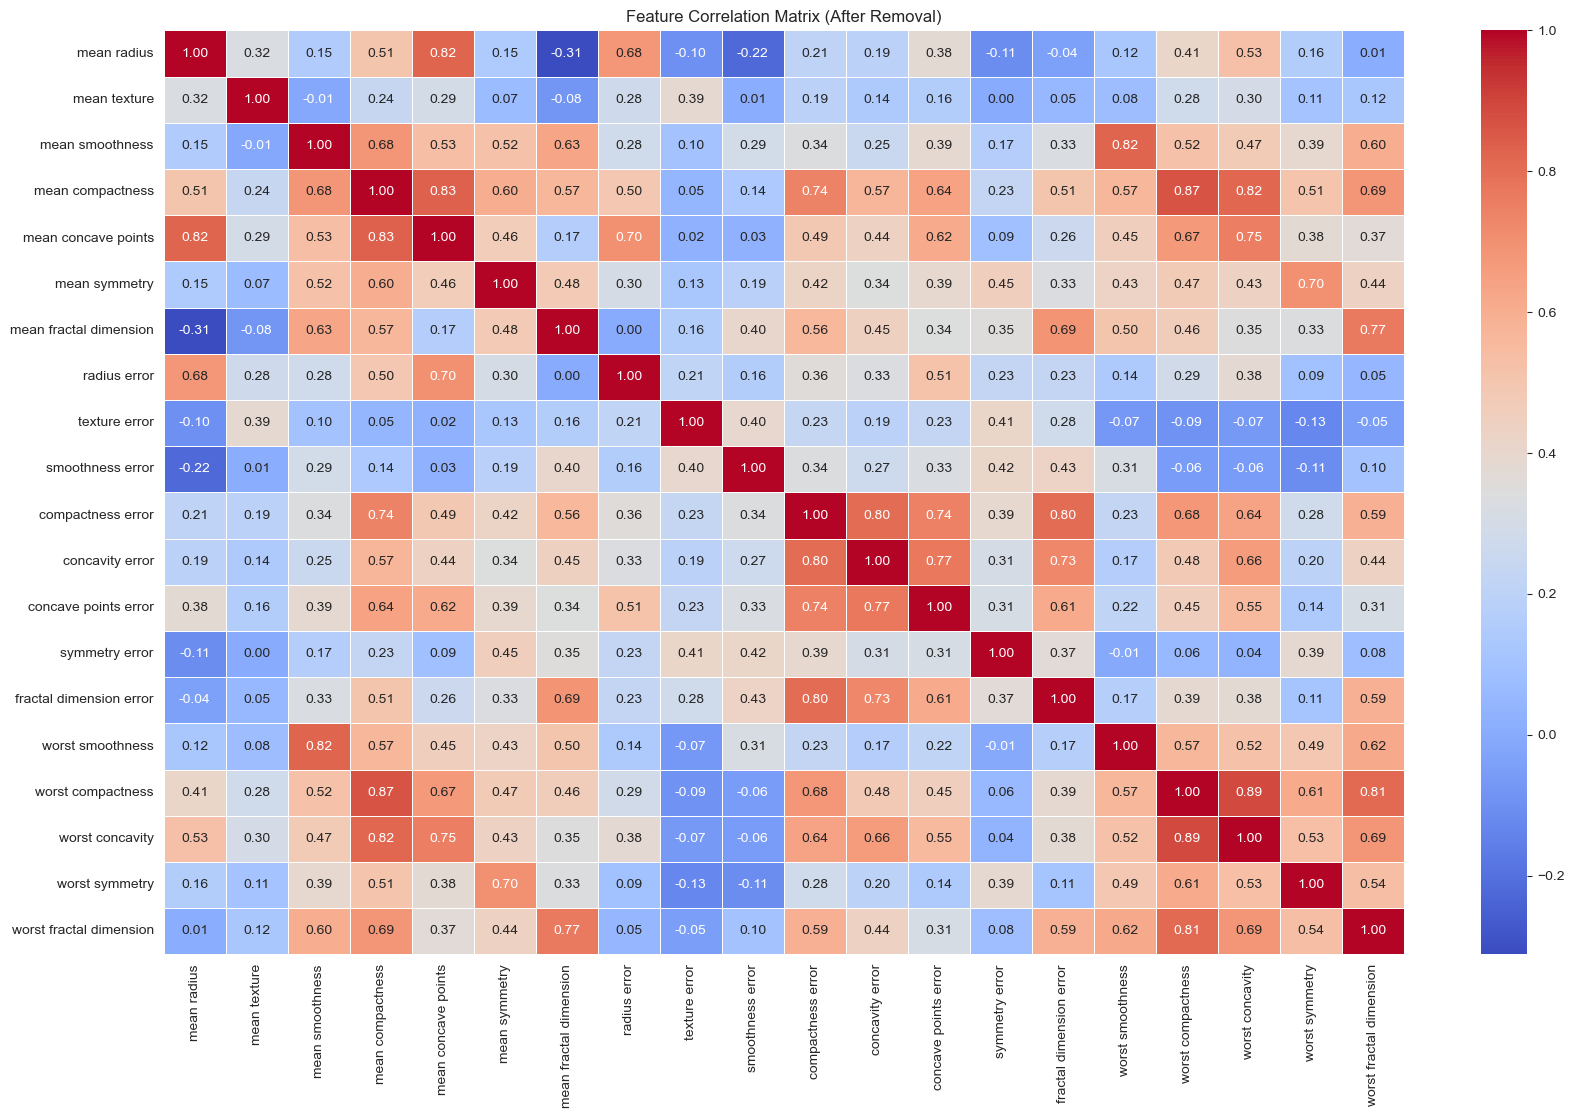

In [15]:
cor_mat_rem = X_rem.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(cor_mat_rem, annot=True, fmt=".2f", cmap="coolwarm", linewidth=0.5)
plt.title("Feature Correlation Matrix (After Removal)")
plt.show()

### Missing Values

Now checking for missing data in the reduced feature set. How missing values are handled depends on how many there are and whether the missingness relates to the diagnosis class. A few missing values can be imputed, but if a feature is mostly empty it is better to drop it entirely.

In [16]:
# Count missing values per column
missing_counts = X_rem.isnull().sum()

# Calculate percentage of missing values
missing_percent = (missing_counts / len(X_rem)) * 100 

# Combine into a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing %': missing_percent.round(2)
})

# Filter to show only columns with missing values
missing_summary = missing_summary[missing_summary['Missing Count'] > 0]
missing_summary

,Missing Count,Missing %
mean smoothness,284,49.91
symmetry error,28,4.92


In [17]:
# Create temporary DataFrame for safe group-based imputation
tmp_df = X_rem[["symmetry error"]].copy()
tmp_df["diagnosis"] = y.reset_index(drop=True)

# Check structure
print(tmp_df.info())
tmp_df.head()

# Count missing per class
miss5_count = tmp_df.groupby("diagnosis")["symmetry error"].apply(lambda x: x.isnull().sum())
print("Missing values per class:\n", miss5_count, "\n")

# Calculate median per class
median5_count = tmp_df.groupby("diagnosis")["symmetry error"].median()
print("Median values per class:\n", median5_count)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   symmetry error  541 non-null    float64
 1   diagnosis       569 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 9.0 KB
None
Missing values per class:
 diagnosis
0     5
1    23
Name: symmetry error, dtype: int64 

Median values per class:
 diagnosis
0    0.01772
1    0.01929
Name: symmetry error, dtype: float64


Group-based imputation fills missing values with the median from the same diagnosis class rather than the overall median. This preserves any difference between malignant and benign distributions for that feature, which a global median would wash out.

In [18]:
# IMPUTE: for each group (diagnosis class), fill missing values with that group's median
tmp_df["symmetry error"] = tmp_df.groupby("diagnosis")["symmetry error"].transform(
    lambda x: x.fillna(x.median())
)

print("Missing values after imputation:", tmp_df["symmetry error"].isnull().sum())

# Reassign to main dataset
X_rem["symmetry error"] = tmp_df["symmetry error"].values
print("Missing values in X_rem (symmetry error):", X_rem["symmetry error"].isnull().sum())

Missing values after imputation: 0
Missing values in X_rem (symmetry error): 0


Mean smoothness has too many missing values to impute reliably, so it gets dropped entirely. Imputing a feature that is mostly missing would just be inventing data.

In [19]:
# Check how many values are missing
print("Missing in mean smoothness:", X_rem["mean smoothness"].isnull().sum())
# Drop the column
print("Shape before drop:", X_rem.shape)
X_rem = X_rem.drop(columns=["mean smoothness"], errors="ignore")
print("Shape after drop:", X_rem.shape)

Missing in mean smoothness: 284
Shape before drop: (569, 20)
Shape after drop: (569, 19)


In [20]:
columns_to_check = ['mean smoothness']

for col in columns_to_check:
    if col in X_rem.columns:
        print(f"'{col}' is still present")
    else:
        print(f"'{col}' has been successfully removed")

'mean smoothness' has been successfully removed


In [21]:
# to catch any remaining missing values across all columns with median imputation
imputer = SimpleImputer(strategy='median')
X_rem_imputed = pd.DataFrame(imputer.fit_transform(X_rem), columns=X_rem.columns)

### Oversampling

The dataset has more benign than malignant samples. Three oversampling methods are compared here: Random Oversampling (duplicates random minority samples), SMOTE (creates synthetic samples by interpolating between existing minority neighbours), and ADASYN (like SMOTE but generates more samples in harder-to-classify regions). ADASYN is used going forward because it focuses synthetic data where the decision boundary is most uncertain.

In [22]:
# pip install imbalanced-learn

In [23]:
ros = RandomOverSampler(random_state=91011)
X_ros, y_ros = ros.fit_resample(X_rem, y)
print("Class distribution after Naive Oversampling:\n", y_ros.value_counts())

Class distribution after Naive Oversampling:
 diagnosis
0    357
1    357
Name: count, dtype: int64


In [24]:
smote = SMOTE(random_state=91011)
X_smote, y_smote = smote.fit_resample(X_rem, y)
print("Class distribution after SMOTE:\n", y_smote.value_counts())

Class distribution after SMOTE:
 diagnosis
0    357
1    357
Name: count, dtype: int64


In [25]:
adasyn = ADASYN(random_state=91011)
X_rem_bal, y_bal = adasyn.fit_resample(X_rem, y)
print("Class distribution after ADASYN:\n", y_bal.value_counts())

Class distribution after ADASYN:
 diagnosis
1    357
0    352
Name: count, dtype: int64


### Feature Scaling

ML models like SVM and Logistic Regression are sensitive to feature scale. If one feature ranges from 0 to 1000 and another from 0 to 1, the model treats the larger one as more important even if it is not. Scaling fixes this. Three scalers are compared: MinMaxScaler (scales to 0-1), StandardScaler (zero mean, unit variance), and MaxAbsScaler (scales by max absolute value). MinMaxScaler is used going forward with the balanced dataset.

In [26]:
# Define the scaler
minmax_scaler = MinMaxScaler()

# Apply it to balanced feature set
X_rem_bal_sc = minmax_scaler.fit_transform(X_rem_bal)

# Save the scaler for next week!
joblib.dump(minmax_scaler, "minmax_scaler.pkl")

# Convert back to DataFrame
X_rem_bal_sc_df = pd.DataFrame(X_rem_bal_sc, 
                                columns=X_rem_bal.columns, 
                                index=X_rem_bal.index)

print(X_rem_bal_sc_df.shape)
X_rem_bal_sc_df.head()

(709, 19)


,mean radius,mean texture,mean compactness,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst smoothness,worst compactness,worst concavity,worst symmetry,worst fractal dimension
0,0.521037,0.022658,0.792037,0.731113,0.686364,0.605518,0.356147,0.120469,0.159296,0.351398,0.135682,0.300625,0.311645,0.183042,0.601136,0.619292,0.568610,0.598462,0.418864
1,0.643144,0.272574,0.181768,0.348757,0.379798,0.141323,0.156437,0.082589,0.119387,0.081323,0.046970,0.253836,0.084539,0.091110,0.347553,0.154563,0.192971,0.233590,0.222878
2,0.601496,0.390260,0.431017,0.635686,0.509596,0.211247,0.229622,0.094303,0.150831,0.283955,0.096768,0.389847,0.205690,0.127006,0.483590,0.385375,0.359744,0.403706,0.213433
3,0.210090,0.360839,0.811361,0.522863,0.776263,1.000000,0.139091,0.175875,0.251453,0.543215,0.142955,0.353665,0.728148,0.287205,0.915472,0.814012,0.548642,1.000000,0.773711
4,0.629893,0.156578,0.347893,0.518390,0.378283,0.186816,0.233822,0.093065,0.332359,0.167918,0.143636,0.357075,0.136179,0.145800,0.437364,0.172415,0.319489,0.157500,0.142595


In [27]:
# z-score normalisation: mean=0, std=1. useful for distance-based models
zscore_scaler = StandardScaler()
X_zscore = zscore_scaler.fit_transform(X_rem_bal)

In [28]:
# scales by dividing by max absolute value. keeps sparsity, range [-1, 1]
maxabs_scaler = MaxAbsScaler()
X_maxabs = maxabs_scaler.fit_transform(X_rem_bal)

## Session 03

Even after removing correlated features, there may still be features that do not actually help the model. Feature selection narrows the set down to the ones that carry the most useful signal. Three methods are compared: VarianceThreshold removes features that barely change across patients, SelectKBest ranks features by statistical association with the target, and RFE recursively drops the least important features based on a model.

In [29]:
# apply low variance filtering (threshold = 0.01)
var_thresh = VarianceThreshold(threshold=0.01)
X_lowvar = var_thresh.fit_transform(X_rem_bal_sc_df)

# get all feature variances
feat_vars = pd.Series(var_thresh.variances_, index=X_rem_bal_sc_df.columns)

# identify removed features
rem_feats = feat_vars[feat_vars < 0.01]

print('Features removed due to low variance:\n')
print(rem_feats.sort_values())

print('Original shape:', X_rem_bal_sc_df.shape)
print('After low variance filtering:', X_lowvar.shape)

Features removed due to low variance:

concavity error            0.004870
fractal dimension error    0.007290
radius error               0.008599
smoothness error           0.008879
dtype: float64
Original shape: (709, 19)
After low variance filtering: (709, 15)


### SelectKBest (Univariate Feature Selection)

SelectKBest with f_classif (ANOVA F-test) scores each feature by how well it separates the two classes. The top 10 are kept. Features with high F-scores and low p-values are the ones that differ most between malignant and benign, so they carry the strongest signal for classification.

In [30]:
# select top 10 features
selector = SelectKBest(score_func=f_classif, k=10)
X_uni = selector.fit_transform(X_rem_bal_sc_df, y_bal)

# get feature names, F-scores, p values
feat_names = X_rem_bal_sc_df.columns
f_scores = selector.scores_
p_vals = selector.pvalues_
p_vals_per = (p_vals * 100).round(2) #convert to percentage

# summary dataframe
feat_scores = pd.DataFrame({
    'Feature': feat_names,
    'F-score': f_scores,
    'p-value': p_vals,
    'p-value (%)': p_vals_per
}).sort_values(by='F-score', ascending=False)

print(feat_scores)
print('Shape before univariate selection:',  X_rem_bal_sc_df.shape)
print('Shape after univariate selection:', X_uni.shape)

                    Feature     F-score        p-value  p-value (%)
3       mean concave points  848.176098  3.836173e-123         0.00
16          worst concavity  572.571987   3.743898e-93         0.00
0               mean radius  440.393783   2.215293e-76         0.00
15        worst compactness  402.084746   3.724430e-71         0.00
2          mean compactness  393.519452   5.811209e-70         0.00
14         worst smoothness  229.957065   3.524538e-45         0.00
6              radius error  206.711862   2.638861e-41         0.00
17           worst symmetry  196.836814   1.252662e-39         0.00
18  worst fractal dimension  141.493135   7.171363e-30         0.00
11     concave points error  129.289281   1.247141e-27         0.00
4             mean symmetry  113.535265   1.094486e-24         0.00
1              mean texture  109.874612   5.391121e-24         0.00
9         compactness error   67.273923   1.114026e-15         0.00
10          concavity error   46.050437   2.4399

### RFE (Recursive Feature Elimination)

RFE takes a model-driven approach. It trains a Logistic Regression, ranks features by their coefficients, drops the weakest one, and repeats until 10 remain. Comparing the RFE selection against SelectKBest shows which features both methods agree on, giving stronger justification for the final feature set.

In [31]:
# define the model 
log_reg = LogisticRegression(max_iter=1000)

# initialize RFE to select top 10 features
rfe = RFE(estimator=log_reg, n_features_to_select=10)
X_rfe = rfe.fit_transform(X_rem_bal_sc_df, y_bal)

# get the mask of selecteed features
rfe_mask = rfe.support_ #Boolean mask True=selected False=not selected)

# get feature names selected by RFE
selected_rfe_feature = X_rem_bal_sc_df.columns[rfe_mask]
print('Top 10 features selected by RFE:\n', selected_rfe_feature.tolist())

# create a ranking table
rfe_ranking = pd.DataFrame({
    'Feature': X_rem_bal_sc_df.columns,
    'RFE Rank': rfe.ranking_
}).sort_values(by='RFE Rank')

print('\nFull RFE feature ranking:\n')
print(rfe_ranking)

Top 10 features selected by RFE:
 ['mean radius', 'mean texture', 'mean concave points', 'mean fractal dimension', 'radius error', 'compactness error', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst symmetry']

Full RFE feature ranking:

                    Feature  RFE Rank
0               mean radius         1
16          worst concavity         1
15        worst compactness         1
14         worst smoothness         1
17           worst symmetry         1
6              radius error         1
9         compactness error         1
3       mean concave points         1
1              mean texture         1
5    mean fractal dimension         1
2          mean compactness         2
13  fractal dimension error         3
12           symmetry error         4
18  worst fractal dimension         5
11     concave points error         6
4             mean symmetry         7
10          concavity error         8
8          smoothness error         9
7             textur

### Building a Pipeline

A pipeline chains all preprocessing steps and the model into a single object. This means imputation, scaling, balancing, feature selection, and classification all happen in one call. It also prevents data leakage because each step only sees the training fold during cross-validation, not the validation data.

In [32]:
# split data into test and train 
X_pipe_train, X_pipe_test, y_pipe_train, y_pipe_test = train_test_split(
    X_rem_bal_sc_df,
    y_bal,
    test_size = 0.2,
    random_state = 91011
)

# build pipeline
pipe = Pipeline([
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler()),
    ('balance', ADASYN(random_state = 91011)),
    ('select', SelectKBest(score_func = f_classif, k = 10)),
    ('model', LogisticRegression(max_iter = 1000))
])

# fit pipe and makes predictions
pipe.fit(X_pipe_train, y_pipe_train)
y_pipe_pred = pipe.predict(X_pipe_test)

# evaluate
print('Confusion Matrix: \n')
print(confusion_matrix(y_pipe_test, y_pipe_pred), '\n')

print('Classification report: \n')
print(classification_report(y_pipe_test, y_pipe_pred))

Confusion Matrix: 

[[79  4]
 [ 5 54]] 

Classification report: 

              precision    recall  f1-score   support

           0       0.94      0.95      0.95        83
           1       0.93      0.92      0.92        59

    accuracy                           0.94       142
   macro avg       0.94      0.93      0.93       142
weighted avg       0.94      0.94      0.94       142



### Comparing Multiple Models Through the Pipeline

Running five different classifiers through the same preprocessing pipeline to see which one performs best on this data. Using the same pipeline for all models keeps the comparison fair because every model gets the same imputation, scaling, and feature selection.

In [33]:
#models to test
model = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state = 91011),
    'Support Vector Machine': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state = 91011),
    'Naive Bayes': GaussianNB()
}

#common preprocession steps
preprocession_steps = [
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler()),
    ('select', SelectKBest(score_func = f_classif, k = 10))
]
for name, model in model.items():
    print(f'\nModel: {name}')

# create and run pipeline
pipe = Pipeline(preprocession_steps + [('model', model)])
pipe.fit(X_pipe_train, y_pipe_train)
y_pipe_pred = pipe.predict(X_pipe_test)

# perfomance
print(classification_report(y_pipe_test, y_pipe_pred))


Model: Logistic Regression

Model: Random Forest

Model: Support Vector Machine

Model: Decision Tree

Model: Naive Bayes
              precision    recall  f1-score   support

           0       0.96      0.82      0.88        83
           1       0.79      0.95      0.86        59

    accuracy                           0.87       142
   macro avg       0.87      0.88      0.87       142
weighted avg       0.89      0.87      0.87       142



## Session 04

An autoencoder is a neural network that compresses data into a smaller representation (the latent space) and then tries to reconstruct the original input. If the reconstruction is good, the latent space has captured the most important patterns in fewer dimensions. This is useful for dimensionality reduction before clustering or visualisation. PCA is also applied as a simpler linear alternative for comparison.

In [34]:
# pip install torch 

### Autoencoder Architecture

The encoder compresses the 19 input features down to 5 latent dimensions. The decoder tries to reconstruct the original 19 features from those 5. If the reconstruction loss is low, the 5 latent dimensions capture most of the information in the original data.

In [35]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super(Autoencoder, self).__init__()
        
        # Compresses the input into a lower-dimensional space (ENCODER)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 12),  # Fully connected layer from input to hidden
            nn.LeakyReLU(),            # Activation function to add non-linearity
            nn.Linear(12, latent_dim), # Hidden to latent space
            nn.LeakyReLU()
        )
        
        # Reconstruct the original input from the latent space (DECODER)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 12), # Latent to hidden
            nn.LeakyReLU(),
            nn.Linear(12, input_dim)   # Hidden back to original input dimensions
        )
    
    def forward(self, x):
        z = self.encoder(x)        # Encode input to latent representation
        x_recon = self.decoder(z)  # Decode back to reconstructed input
        return x_recon, z

In [36]:
# convert preprocessed data to PyTorch tensor
X_tensor = torch.tensor(X_rem_bal_sc, dtype=torch.float32)

# set seed for reproducibility
torch.manual_seed(91011)

In [37]:
input_dim = X_rem_bal_sc.shape[1] # number of original features in dataset
latent_dim = 5 # compressing down to 5

model = Autoencoder(input_dim=input_dim, latent_dim=latent_dim)

# MSE loss measures how well the decoder reconstructs the original input
criterion = nn.MSELoss()

# Adam optimiser with learning rate 0.01
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [38]:
# training loop: 1000 epochs, printing loss every 100 to check convergence
for epoch in range (1000):
    optimizer.zero_grad() 
    recon, z = model(X_tensor)
    loss = criterion(recon, X_tensor)
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f'Epoch {epoch}, Loss: {loss.item():.4f}')

Epoch 0, Loss: 0.1545
Epoch 100, Loss: 0.0087
Epoch 200, Loss: 0.0047
Epoch 300, Loss: 0.0045
Epoch 400, Loss: 0.0044
Epoch 500, Loss: 0.0042
Epoch 600, Loss: 0.0035
Epoch 700, Loss: 0.0033
Epoch 800, Loss: 0.0033
Epoch 900, Loss: 0.0032


Extracting the latent representations from the trained encoder. These 5 compressed features can now be used for clustering or visualisation instead of the original 19.

In [39]:
with torch.no_grad():
    _, z_encoded = model(X_tensor)

# convert latent space to DataFrame for further use
X_rem_bal_sc_ae = pd.DataFrame(
    z_encoded.numpy(),
    columns=[f"latent_{i+1}" for i in range(latent_dim)],
    index=X_rem_bal.index
)

print(X_rem_bal_sc_ae.head())

   latent_1  latent_2  latent_3  latent_4  latent_5
0 -0.052809 -0.015255  1.205612  1.496582  0.481800
1 -0.046571 -0.012985  0.554004  0.565949  0.207313
2 -0.066855 -0.017614  0.996740  0.902543  0.449354
3 -0.069557 -0.016370  1.239661  2.115845  1.112805
4 -0.054749 -0.014835  0.765705  0.686869  0.342716


### PCA (Principal Component Analysis)

PCA is a simpler, linear alternative to the autoencoder. It finds the directions of maximum variance in the data and projects onto those. Two components are used here for visualisation. The explained variance ratio shows how much information each component captures.

In [40]:
pca = PCA(n_components=2)
X_rem_bal_sc_pca = pca.fit_transform(X_rem_bal_sc)

print("PCA output shape:", X_rem_bal_sc_pca.shape)
print("Variance explained by each component:", pca.explained_variance_ratio_.round(3))
print("Total variance explained:", pca.explained_variance_ratio_.sum().round(3))

PCA output shape: (709, 2)
Variance explained by each component: [0.489 0.152]
Total variance explained: 0.641


### Systematic Review in Python

Exploring whether PubMed searches and NLP can be automated to support evidence synthesis. This is not part of the ML pipeline but was introduced in the lab session as a separate skill. The search looks for recent papers on CNNs applied to breast cancer mammography.

In [41]:
# pip install spacy
# pip install biopython

In [42]:
Entrez.email = 'your_email@example.com'

In [43]:
today = datetime.today().strftime("%Y/%m/%d")
one_year_ago = (datetime.today() - timedelta(days=365)).strftime("%Y/%m/%d")
five_years_ago = (datetime.today() - timedelta(days=5*365)).strftime("%Y/%m/%d")

print(f"Start date (5 years ago): {five_years_ago}, End date: {today}")
print(f"Start date (1 year ago): {one_year_ago}, End date: {today}")

Start date (5 years ago): 2021/04/24, End date: 2026/04/23
Start date (1 year ago): 2025/04/23, End date: 2026/04/23


In [44]:
def search_pubmed(query, max_results=None):
    handle = Entrez.esearch(db="pubmed", term=query, retmax=1)
    record = Entrez.read(handle)
    total_results = int(record["Count"])

    max_results = total_results if max_results is None else min(max_results, total_results)

    handle = Entrez.esearch(db="pubmed", term=query, retmax=max_results)
    record = Entrez.read(handle)
    handle.close()

    return total_results, record["IdList"]

def get_abstracts(pubmed_ids):
    ids = ",".join(pubmed_ids)
    handle = Entrez.efetch(db="pubmed", id=ids, rettype="abstract", retmode="text")
    abstracts = handle.read()
    handle.close()
    return abstracts

bc_query = (
    f'("breast cancer"[Title/Abstract] AND "mammography"[Title/Abstract] '
    f'AND ("convolutional neural network"[Title/Abstract] OR "CNN"[Title/Abstract])) '
    f'AND ("{one_year_ago}"[Date - Publication] : "{today}"[Date - Publication]) '
    f'AND English[Language]'
)

In [45]:
count, pubmed_ids = search_pubmed(bc_query)

print(f"Total Results: {count}")
print(f"PubMed IDs ({len(pubmed_ids)} articles): {pubmed_ids}")

Total Results: 38
PubMed IDs (38 articles): ['41940102', '41900992', '41813686', '41750667', '41716062', '41588757', '41486277', '41470239', '41464144', '41416718', '41402449', '41374420', '41228243', '41226009', '41223545', '41171652', '41162641', '41149829', '41131156', '41084046', '41041579', '41003364', '40989432', '40989387', '40983013', '40935875', '40911159', '40863457', '40721416', '40652141', '40608200', '40600038', '40428767', '40054167', '40020549', '39887755', '39643464', '39313715']


In [46]:
abstracts = get_abstracts(pubmed_ids)
print(f"Total Abstracts Retrieved: {len(pubmed_ids)}")
print(abstracts[:10000]) # Show first 1000 characters

Total Abstracts Retrieved: 38
1. Front Artif Intell. 2026 Mar 19;9:1770667. doi: 10.3389/frai.2026.1770667. 
eCollection 2026.

Transformers meet CNNs for insights into breast mass classification from 
histopathological images.

Anand V(1), Khajuria A(2).

Author information:
(1)Department of Computer Science and Engineering, Akal University, Bathinda, 
Punjab, India.
(2)Department of Chemistry, Akal University, Bathinda, Punjab, India.

INTRODUCTION: Breast cancer remains one of the leading causes of cancer-related 
deaths among women worldwide, highlighting the critical need for accurate 
histopathological diagnosis and reliable decision-support systems to improve 
diagnostic sensitivity and reduce false-negative outcomes.
METHODS: In this research, a deep learning-based approach for binary 
classification of breast cancer into benign and malignant categories utilizing 
histopathological images is presented. A dataset comprising 10,000 
high-resolution histopathology images was used 

In [47]:
# !python -m spacy download en_core_web_sm

In [48]:
# Load the NLP model
nlp = spacy.load("en_core_web_sm")

text_data = " ".join(wbc_df.columns.astype(str))

# Process the text
doc = nlp(text_data)

# Extract clean tokens (lemmatised, lowercase, no stop words, no punctuation)
tokens = [token.lemma_.lower() for token in doc 
          if token.is_alpha and not token.is_stop]

# Get the top 20 most frequent words
common_tokens = Counter(tokens).most_common(20)

print("Most common tokens in the literature:")
for word, count in common_tokens:
    print(f"{word}: {count}")

Most common tokens in the literature:
mean: 10
error: 10
bad: 6
worst: 4
radius: 3
texture: 3
perimeter: 3
area: 3
smoothness: 3
compactness: 3
concavity: 3
concave: 3
point: 3
symmetry: 3
fractal: 3
dimension: 3
diagnosis: 1


## Session 05

Clustering is unsupervised, meaning the algorithms try to find groups in the data without seeing the diagnosis labels. Three methods are compared: GMM assumes data comes from multiple Gaussian distributions, Bayesian GMM does the same but can automatically decide how many clusters it actually needs, and DBSCAN groups by density without requiring a predefined number of clusters. The Adjusted Rand Index (ARI) measures how well each algorithm's clusters match the true benign/malignant labels.

In [49]:
pca = PCA(n_components=2)
X_rem_bal_sc_pca = pca.fit_transform(X_rem_bal_sc)

# convert to dataframe since PCA outputs as numpy array
X_rem_bal_sc_pca_df = pd.DataFrame(X_rem_bal_sc_pca, columns=["PCA_1", "PCA_2"])

#GMM we tell it to find 2 clusters
gmm = GaussianMixture(n_components=2, random_state=91011)
gmm_clusters = gmm.fit_predict(X_rem_bal_sc_pca_df)

# BGMM we give it up to 10 but it decides how many it actually needs
bgmm = BayesianGaussianMixture(n_components=10, random_state=91011, max_iter=500)
bgmm_clusters = bgmm.fit_predict(X_rem_bal_sc_pca_df)

# DBSCAN groups by density, no need to specify number of clusters
dbscan = DBSCAN(eps=1.5, min_samples=5)
dbscan_clusters = dbscan.fit_predict(X_rem_bal_sc_pca_df)

gmm_ars = adjusted_rand_score(y_bal, gmm_clusters)
bgmm_ars = adjusted_rand_score(y_bal, bgmm_clusters)
dbscan_ars = adjusted_rand_score(y_bal, dbscan_clusters)

print("Adjusted Rand Index (ARI) Scores:")
print("GMM ARI:", gmm_ars)
print("Bayesian GMM ARI:", bgmm_ars)
print("DBSCAN ARI:", dbscan_ars)

Adjusted Rand Index (ARI) Scores:
GMM ARI: 0.4946478999354869
Bayesian GMM ARI: 0.41547426993659853
DBSCAN ARI: 0.0


### Clustering Results

Plotting all three clustering outputs side by side on the PCA-reduced data, then comparing against the true class labels to see which algorithm best recovered the real structure.

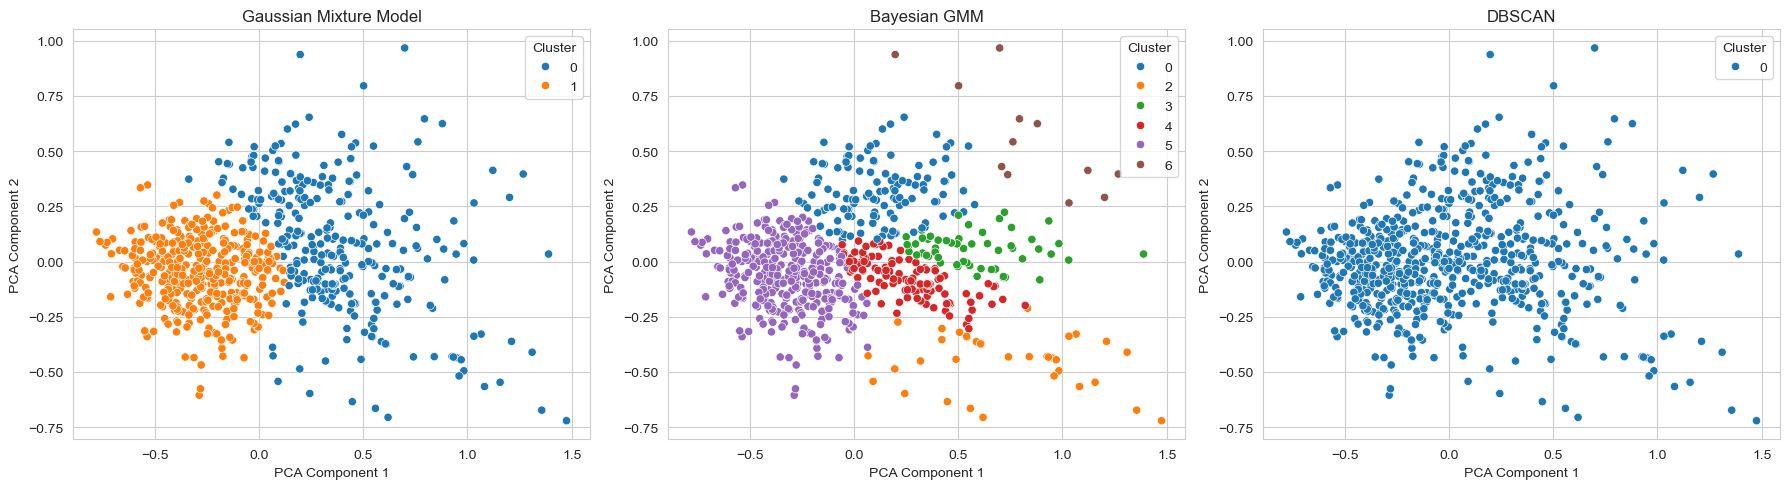

In [50]:
# set up subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# GMM
sns.scatterplot(
    x=X_rem_bal_sc_pca_df["PCA_1"],
    y=X_rem_bal_sc_pca_df["PCA_2"],
    hue=gmm_clusters,
    palette="tab10",
    ax=axes[0]
)
axes[0].set_title("Gaussian Mixture Model")

# BGMM
sns.scatterplot(
    x=X_rem_bal_sc_pca_df["PCA_1"],
    y=X_rem_bal_sc_pca_df["PCA_2"],
    hue=bgmm_clusters,
    palette="tab10",
    ax=axes[1]
)
axes[1].set_title("Bayesian GMM")

# DBSCAN
sns.scatterplot(
    x=X_rem_bal_sc_pca_df["PCA_1"],
    y=X_rem_bal_sc_pca_df["PCA_2"],
    hue=dbscan_clusters,
    palette="tab10",
    ax=axes[2]
)
axes[2].set_title("DBSCAN")

for ax in axes:
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")
    ax.legend(title="Cluster")

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

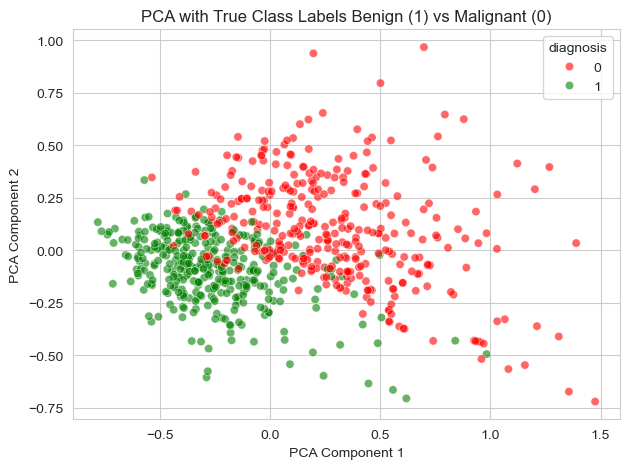

In [51]:
# true class labels on the same PCA plot for comparison against the clustering results
sns.scatterplot(
    x=X_rem_bal_sc_pca_df["PCA_1"],
    y=X_rem_bal_sc_pca_df["PCA_2"],
    hue=y_bal, 
    palette=["red", "green"],
    alpha=0.6
)
plt.title("PCA with True Class Labels Benign (1) vs Malignant (0)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.tight_layout()
plt.show

## Session 06:

Before running a Bayesian classifier, working through Bayes' Theorem by hand to build intuition for how priors and likelihoods shape posterior probabilities. Two examples: the Steve librarian/farmer problem from the lecture, and a mammography screening scenario that shows why PPV can be shockingly low even with a good test when the disease is rare.

### Steve the Librarian or Farmer

Given a description that sounds like a librarian, what is the probability Steve actually is one? Base rates matter. Even if the description fits a librarian perfectly, there are 200 farmers and only 10 librarians in the population, so the prior heavily favours farmer.

In [52]:
P_librarian = 10 / (10 + 200)
P_farmer = 200 / (10 + 200)

P_desc_given_librarian = 0.4
P_desc_given_farmer = 0.1

numerator_L = P_desc_given_librarian * P_librarian 
numerator_F = P_desc_given_farmer * P_farmer
evidence = numerator_L + numerator_F

P_librarian_given_desc = numerator_L / evidence
P_farmer_given_desc = numerator_F / evidence

print(f"Probability the person is a Librarian given the description: {P_librarian_given_desc:.2%}")
print(f"Probability the person is a Farmer given the description: {P_farmer_given_desc:.2%}")

Probability the person is a Librarian given the description: 16.67%
Probability the person is a Farmer given the description: 83.33%


Flipping the base rates to 200 librarians and 10 farmers. Now the prior supports the description instead of fighting it, so the posterior swings dramatically. Same evidence, different conclusion, all because the base rates changed.

In [53]:
P_librarian_flipped = 200 / (200 + 10)
P_farmer_flipped = 10 / (200 + 10)

numerator_L_flipped = P_desc_given_librarian * P_librarian_flipped
numerator_F_flipped = P_desc_given_farmer * P_farmer_flipped
evidence_flipped = numerator_L_flipped + numerator_F_flipped

P_lib_post_flipped = numerator_L_flipped / evidence_flipped
P_farm_post_flipped = numerator_F_flipped / evidence_flipped

print("Flipped base rates (200 librarians, 10 farmers)")
print(f"P(Librarian description): {P_lib_post_flipped:.2%}")
print(f"P(Farmer description): {P_farm_post_flipped:.2%}")
print(f"\nNow Steve is almost certainly a librarian because the prior supports it too.")

Flipped base rates (200 librarians, 10 farmers)
P(Librarian description): 98.77%
P(Farmer description): 1.23%

Now Steve is almost certainly a librarian because the prior supports it too.


Testing what happens when the description is extremely distinctive (90% match for librarian, 1% for farmer). A strong enough likelihood can overcome unfavourable base rates, but it has to be very strong.

In [54]:
P_desc_given_librarian_strong = 0.9  
P_desc_given_farmer_weak = 0.01      

num_L_strong = P_desc_given_librarian_strong * P_librarian
num_F_strong = P_desc_given_farmer_weak * P_farmer
ev_strong = num_L_strong + num_F_strong

print("Stronger description match")
print(f"P(Librarian description): {num_L_strong / ev_strong:.2%}")
print(f"P(Farmer description): {num_F_strong / ev_strong:.2%}")
print(f"\nA really distinctive description can overcome unfavourable base rates.")
print(f"But notice it took 90% vs 1% to make it happen with 10 vs 200 people.")

Stronger description match
P(Librarian description): 81.82%
P(Farmer description): 18.18%

A really distinctive description can overcome unfavourable base rates.
But notice it took 90% vs 1% to make it happen with 10 vs 200 people.


### Mammography Screening: PPV and Prevalence

A mammogram with 90% sensitivity and 91% specificity sounds good. But at 1% cancer prevalence, most positive results are false alarms. This is the base rate problem applied to healthcare, and it directly connects to how we interpret model outputs later.

In [55]:
P_cancer = 0.01
P_no_cancer = 1 - P_cancer

P_pos_given_cancer = 0.90
specificity = 0.91
P_pos_given_no_cancer = 1 - specificity

numerator = P_pos_given_cancer * P_cancer
denominator = (P_pos_given_cancer * P_cancer) + (P_pos_given_no_cancer * P_no_cancer)

P_cancer_given_positive = numerator / denominator 

print(f"Probability that a woman who tests positive actually has cancer: {P_cancer_given_positive:.2%}")
print(f"\nonly about 9%. so roughly 1 in 11 positive results is actually cancer.")
print(f"feels wrong but it's because the disease is rare at 1% prevalence.")
print(f"most of the positives are coming from the huge healthy group, not the tiny sick group.")

Probability that a woman who tests positive actually has cancer: 9.17%

only about 9%. so roughly 1 in 11 positive results is actually cancer.
feels wrong but it's because the disease is rare at 1% prevalence.
most of the positives are coming from the huge healthy group, not the tiny sick group.


In [56]:
total = 1000
cancer_cases = int(total * P_cancer)
non_cancer_cases = total - cancer_cases

TP = int(cancer_cases * P_pos_given_cancer)
FN = cancer_cases - TP

FP = int(non_cancer_cases * P_pos_given_no_cancer)
TN = non_cancer_cases - FP

print(f"True Positives (TP): {TP}")
print(f"False Negatives (FN): {FN}")
print(f"False Positives (FP): {FP}")
print(f"True Negatives (TN): {TN}")

PPV = TP / (TP + FP)
print(f"PPV/Precision (TP / (TP + FP)): {PPV:.2%}")
print(f"so out of {TP + FP} positive results, only {TP} actually have cancer.")

True Positives (TP): 9
False Negatives (FN): 1
False Positives (FP): 89
True Negatives (TN): 901
PPV/Precision (TP / (TP + FP)): 9.18%
so out of 98 positive results, only 9 actually have cancer.


Looping through different prevalence rates to show the pattern: as prevalence increases, PPV increases. At 0.1% prevalence nearly every positive is a false alarm. At 50% most positives are real. This is why the same test performs differently depending on the population it is used on.

In [57]:
for prev in [0.001, 0.01, 0.10, 0.50]:
    p_c = prev
    p_nc = 1 - prev
    num = P_pos_given_cancer * p_c
    den = num + (P_pos_given_no_cancer * p_nc)
    ppv = num / den
    
    tp = int(1000 * p_c * P_pos_given_cancer)
    fp = int(1000 * p_nc * P_pos_given_no_cancer)
    
    print(f"Prevalence: {prev:>5.1%} , PPV: {ppv:.2%} , "
          f"In 1000 people: {tp} TP vs {fp} FP")

print(f"\nthe pattern is clear: higher prevalence = higher PPV.")
print(f"at 0.1% prevalence basically every positive is a false alarm.")
print(f"at 50% most positives are real. prevalence changes everything.")

Prevalence:  0.1% , PPV: 0.99% , In 1000 people: 0 TP vs 89 FP
Prevalence:  1.0% , PPV: 9.17% , In 1000 people: 9 TP vs 89 FP
Prevalence: 10.0% , PPV: 52.63% , In 1000 people: 90 TP vs 80 FP
Prevalence: 50.0% , PPV: 90.91% , In 1000 people: 450 TP vs 44 FP

the pattern is clear: higher prevalence = higher PPV.
at 0.1% prevalence basically every positive is a false alarm.
at 50% most positives are real. prevalence changes everything.


### Gaussian Naive Bayes on WBC

Now applying Bayes to actual classification. GaussianNB assumes each feature follows a normal distribution within each class and that all features are independent. The independence assumption is strong and probably wrong for this dataset (cell radius and perimeter are obviously related), but NB often performs surprisingly well anyway because it only needs to get the ranking of probabilities right, not the exact values.

In [58]:
# drop NaN rows first, THEN split
X_clean = X.dropna()
y_clean = y[X_clean.index]

X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# fit and predict
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test)

print("\nGaussian Naive Bayes Classification Report:")
print(classification_report(y_test, y_pred_gnb))

Training set: 212 samples
Test set: 54 samples

Gaussian Naive Bayes Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95        19
           1       0.97      0.97      0.97        35

    accuracy                           0.96        54
   macro avg       0.96      0.96      0.96        54
weighted avg       0.96      0.96      0.96        54



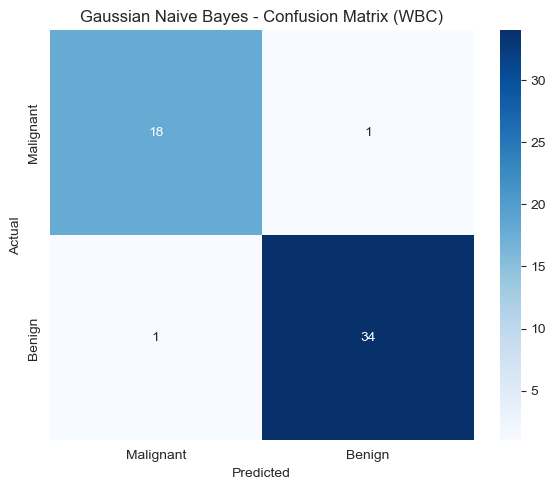

TN: 18 | FP: 1 | FN: 1 | TP: 34

False Negatives (missed malignant): 1
in healthcare FN is the scary one. you're telling someone they're fine when they're not.
this links back to the Bayes' stuff above.


In [59]:
cm = confusion_matrix(y_test, y_pred_gnb)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant', 'Benign'],
            yticklabels=['Malignant', 'Benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gaussian Naive Bayes - Confusion Matrix (WBC)')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")
print(f"\nFalse Negatives (missed malignant): {fn}")
print(f"in healthcare FN is the scary one. you're telling someone they're fine when they're not.")
print(f"this links back to the Bayes' stuff above.")

In [60]:
ppv_model = tp / (tp + fp) if (tp + fp) > 0 else 0
npv_model = tn / (tn + fn) if (tn + fn) > 0 else 0
sensitivity_model = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity_model = tn / (tn + fp) if (tn + fp) > 0 else 0

print(f"Model Performance:")
print(f"  Sensitivity (Recall): {sensitivity_model:.2%}")
print(f"  Specificity:          {specificity_model:.2%}")
print(f"  PPV (Precision):      {ppv_model:.2%}")
print(f"  NPV:                  {npv_model:.2%}")

print(f"""
How this connects to Bayes' Theorem:
- earlier the mammography PPV was only 9% because prevalence was just 1%
- here the PPV is much higher because the WBC dataset is roughly 63% benign / 37% malignant
- that's a way higher 'prevalence' than 1%, so the model looks great on paper
- but if you deployed this on a general population where cancer rates are low,
  PPV would tank just like the mammography example showed
- always ask: what population is this model actually going to be used on?
""")

Model Performance:
  Sensitivity (Recall): 97.14%
  Specificity:          94.74%
  PPV (Precision):      97.14%
  NPV:                  94.74%

How this connects to Bayes' Theorem:
- earlier the mammography PPV was only 9% because prevalence was just 1%
- here the PPV is much higher because the WBC dataset is roughly 63% benign / 37% malignant
- that's a way higher 'prevalence' than 1%, so the model looks great on paper
- but if you deployed this on a general population where cancer rates are low,
  PPV would tank just like the mammography example showed
- always ask: what population is this model actually going to be used on?



## Session 07

Training full classifiers now rather than using them to demonstrate pipelines. Random Forest builds an ensemble of decision trees and uses permutation importance to show which features actually drive predictions. SVM finds the optimal separating boundary and provides decision scores that indicate how confident the model is about each prediction, which has clinical value for flagging uncertain cases.

### Random Forest

Fitting with 1000 trees for a stable ensemble. Training time is tracked because in a real deployment, how long a model takes to train and predict matters for workflow integration.

In [61]:
start_time = time.time()

rf = RandomForestClassifier(n_estimators = 1000, random_state = 91011)
rf.fit(X_train, y_train)

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

Training time: 0.49 seconds


In [62]:
y_pred_rf = rf.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.95      0.95        19
           1       0.97      0.97      0.97        35

    accuracy                           0.96        54
   macro avg       0.96      0.96      0.96        54
weighted avg       0.96      0.96      0.96        54

Confusion Matrix:
 [[18  1]
 [ 1 34]]


### Permutation Feature Importance

The built-in feature_importances_ in Random Forest uses mean decrease in impurity (Gini), which can overrate features with many split points. Permutation importance is more reliable because it shuffles each feature and measures how much accuracy actually drops. If shuffling a feature barely changes anything, it was not really helping.

In [63]:
perm_importance = permutation_importance(rf, X_test, y_test, n_repeats = 10, random_state = 91011)

# convert to df
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm_importance.importances_mean,
    'Importance Std': perm_importance.importances_std
})

# Sort features by importance in descending order; this makes for nicer viewing
importance_df_sorted = importance_df.sort_values(by='Importance Mean', ascending=False)

print(importance_df_sorted)

                    Feature  Importance Mean  Importance Std
27     worst concave points         0.012963        0.008486
0               mean radius         0.000000        0.000000
1              mean texture         0.000000        0.000000
28           worst symmetry         0.000000        0.000000
26          worst concavity         0.000000        0.000000
25        worst compactness         0.000000        0.000000
24         worst smoothness         0.000000        0.000000
22          worst perimeter         0.000000        0.000000
21            worst texture         0.000000        0.000000
20             worst radius         0.000000        0.000000
19  fractal dimension error         0.000000        0.000000
18           symmetry error         0.000000        0.000000
17     concave points error         0.000000        0.000000
16          concavity error         0.000000        0.000000
15        compactness error         0.000000        0.000000
14         smoothness er

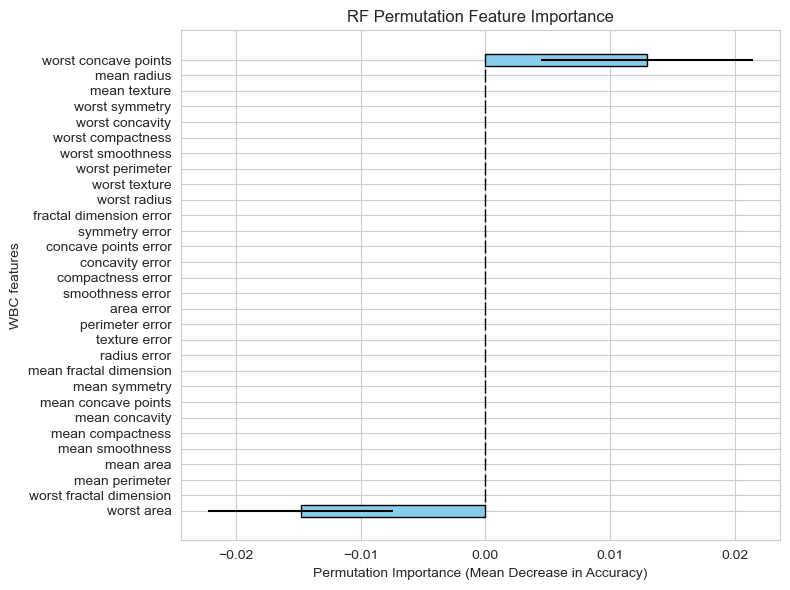

In [64]:
plt.figure(figsize=(8, 6))
plt.barh(importance_df_sorted['Feature'], importance_df_sorted['Importance Mean'], xerr=importance_df_sorted['Importance Std'], color='skyblue', edgecolor='black')
plt.xlabel('Permutation Importance (Mean Decrease in Accuracy)')
plt.ylabel('WBC features')
plt.title('RF Permutation Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### SVM (Support Vector Machine)

Starting with a linear kernel to see if the classes are linearly separable in the original feature space. Then switching to RBF to capture non-linear boundaries. probability=True is set so decision scores and predict_proba are available for threshold analysis later.

In [65]:
svm = SVC(kernel='linear', probability=True)
svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))

Confusion Matrix:
 [[16  3]
 [ 1 34]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.84      0.89        19
           1       0.92      0.97      0.94        35

    accuracy                           0.93        54
   macro avg       0.93      0.91      0.92        54
weighted avg       0.93      0.93      0.92        54



Switching to RBF kernel to check if a non-linear boundary improves performance over the linear kernel.

In [66]:
svm_rbf = SVC(kernel='rbf', probability=True)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
print("RBF Kernel Classification Report:\n", classification_report(y_test, y_pred_rbf))

RBF Kernel Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.84      0.89        19
           1       0.92      0.97      0.94        35

    accuracy                           0.93        54
   macro avg       0.93      0.91      0.92        54
weighted avg       0.93      0.93      0.92        54



### Decision Scores

The decision function returns each sample's signed distance from the decision boundary. Samples close to the boundary (small absolute score) are the ones the model is least sure about. In a clinical setting, these uncertain cases are the ones that should be flagged for human review rather than trusted blindly.

In [67]:
y_pred = svm.predict(X_test)

In [68]:
# distance from decision boundary
decision_scores = svm.decision_function(X_test)

# Create a dataframe to inspect decision scores
results_df = pd.DataFrame({
    'Ground Truth': y_test.values,
    'Predicted Class': y_pred,
    'Decision Score': decision_scores
})

print(results_df.head(10))

results_df['Distance from Boundary'] = results_df['Decision Score'].abs()

results_df_sorted = results_df.sort_values(by='Distance from Boundary')
print(results_df_sorted.head(10))

   Ground Truth  Predicted Class  Decision Score
0             1                1        9.173382
1             1                1        5.083414
2             1                1       14.918552
3             1                0       -2.185572
4             1                1       19.767335
5             1                1        6.995300
6             0                0       -3.811652
7             1                1       12.112633
8             1                1        1.479090
9             0                0      -12.742834
    Ground Truth  Predicted Class  Decision Score  Distance from Boundary
48             0                1        0.820664                0.820664
8              1                1        1.479090                1.479090
25             1                1        2.016609                2.016609
3              1                0       -2.185572                2.185572
17             0                1        3.121159                3.121159
6              0 

## Session 08

Building a feedforward neural network in PyTorch for binary classification on the WBC data. This is a different approach from the sklearn models above because the network learns its own feature representations through backpropagation rather than relying on hand-picked features. The architecture is simple: two hidden layers (64 and 32 neurons) with ReLU activation and a sigmoid output for binary prediction.

In [69]:
# check for Apple Silicon GPU (MPS)
if torch.backends.mps.is_available():
    device = torch.device("mps")
print(f"Using device: {device}")

Using device: mps


### Converting Data to Tensors

PyTorch cannot work with pandas DataFrames or numpy arrays directly. The data needs converting to tensors and moving to the chosen device (GPU or CPU) before training.

In [70]:
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1).to(device)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1).to(device)

print(f'X_train_tensor shape: {X_train_tensor.shape}')
print(f'y_train_tensor shape: {y_train_tensor.shape}')

X_train_tensor shape: torch.Size([212, 30])
y_train_tensor shape: torch.Size([212, 1])


### Network Architecture

Two hidden layers with ReLU activation. The final layer uses sigmoid to output a probability between 0 and 1 for binary classification. BCELoss (binary cross-entropy) is the standard loss function for this setup, and Adam is the optimiser.

In [71]:
class NeuralNet(nn.Module):
    def __init__(self, input_dim):          
        super(NeuralNet, self).__init__()   
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def forward(self, x):                 
        return self.net(x)                

In [72]:
input_dim = X_train.shape[1]
model = NeuralNet(input_dim).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

print(model)

NeuralNet(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


In [73]:
# training loop: 1000 epochs, printing loss every 100 to track convergence
epochs = 1000
start_time = time.time()

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    output = model(X_train_tensor)
    loss = criterion(output, y_train_tensor)
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

Epoch 0, Loss: 4.0044
Epoch 100, Loss: 35.3774
Epoch 200, Loss: 35.3774
Epoch 300, Loss: 35.3774
Epoch 400, Loss: 35.3774
Epoch 500, Loss: 35.3774
Epoch 600, Loss: 35.3774
Epoch 700, Loss: 35.3774
Epoch 800, Loss: 35.3774
Epoch 900, Loss: 35.3774
Training time: 1.25 seconds


### Evaluation

Switching the model to eval mode turns off dropout and batch normalisation (not used here but good practice). Predictions are thresholded at 0.5 to convert probabilities to binary class labels.

In [74]:
model.eval()
with torch.no_grad():
    y_prob = model(X_test_tensor).cpu().numpy()
    y_pred = (y_prob >= 0.5).astype(int)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.6481
Confusion Matrix:
 [[ 0 19]
 [ 0 35]]


## Session 09

A single train/test split can be lucky or unlucky depending on which patients end up where. Cross-validation gives a more honest estimate by running the model across multiple splits. GridSearchCV then searches for the best hyperparameters using cross-validation internally. Finally, the decision threshold is adjusted because in healthcare the default 0.5 cutoff may not be the right balance between catching malignant cases and avoiding false alarms.

In [75]:
# fresh split with stratify to keep class proportions consistent
X_clean = X.dropna()
y_clean = y[X_clean.index]

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean,
    test_size=0.2,
    stratify=y_clean,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Training samples: 212
Test samples: 54


### Cross-Validation

5-fold cross-validation on the linear SVM. Each fold uses a different 80/20 split of the training data, so the mean accuracy is more stable than any single split result.

In [76]:
svm_model = SVC(kernel='linear', C=1)

scores = cross_val_score(svm_model, X_train, y_train, cv=5)

print("Cross-Validation Scores:", scores)
print("Mean Accuracy:", scores.mean())

Cross-Validation Scores: [0.97674419 0.86046512 0.95238095 0.95238095 0.92857143]
Mean Accuracy: 0.934108527131783


### GridSearchCV

Trying different combinations of C, kernel, and gamma to find the best SVM configuration. The grid searches linear and RBF kernels separately because gamma only applies to RBF. Each combination is evaluated with 5-fold cross-validation so the best parameters are not just overfitting to one split.

In [77]:
param_grid = [
    {'C': [0.1, 1, 10], 'kernel': ['linear']},
    {'C': [0.1, 1, 10], 'gamma': [0.01, 0.001], 'kernel': ['rbf']}
]

grid = GridSearchCV(SVC(probability=True), param_grid, cv=5)
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

Best Parameters: {'C': 10, 'kernel': 'linear'}
Best CV Score: 0.9435215946843855


In [78]:
# evaluate the best model from grid search on the held-out test set
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97        19
           1       1.00      0.97      0.99        35

    accuracy                           0.98        54
   macro avg       0.97      0.99      0.98        54
weighted avg       0.98      0.98      0.98        54



### Decision Threshold Adjustment

The default 0.5 threshold treats both error types as equally bad. But in cancer screening, missing a malignant case (false negative) is worse than a false alarm (false positive). Lowering the threshold makes the model flag more cases as malignant, which increases sensitivity at the cost of more false positives. The right threshold depends on how the clinical team weighs missed cancers against unnecessary follow-up.

In [79]:
y_probs = best_model.predict_proba(X_test)[:, 1]

threshold = 0.3
y_pred_thresh = (y_probs >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred_thresh)
sensitivity = recall_score(y_test, y_pred_thresh)
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
ppv = precision_score(y_test, y_pred_thresh)

print("Threshold:", threshold)
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)
print("PPV:", ppv)
print("Confusion Matrix:\n", cm)

Threshold: 0.3
Sensitivity: 1.0
Specificity: 0.8421052631578947
PPV: 0.9210526315789473
Confusion Matrix:
 [[16  3]
 [ 0 35]]
